# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

# 1.

In [1]:
import pandas as pd

diabetes = pd.read_csv("data/diabetes.csv")

In [ ]:
print(pd.crosstab(diabetes['treatment'], diabetes['outcome']))

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143


In [6]:
lif_avg = (diabetes.loc[diabetes['treatment']=='lifestyle', 'outcome']=='success').mean()
met_avg = (diabetes.loc[diabetes['treatment']=='met', 'outcome']=='success').mean()
ros_avg = (diabetes.loc[diabetes['treatment']=='rosi', 'outcome']=='success').mean()

print(f'Average Lifestyle Outcome: {lif_avg}')
print(f'Average Met Outcome: {met_avg}')
print(f'Average Rosi Outcome: {ros_avg}')

Average Lifestyle Outcome: 0.5341880341880342
Average Met Outcome: 0.4827586206896552
Average Rosi Outcome: 0.6137339055793991


# 2.

In [11]:
B = 10000

#Lifestyle

df_lif = diabetes.loc[diabetes['treatment'] == 'lifestyle']
outcome_lif = []

for t in range(B):
    df_lif_t = df_lif.sample(frac=1.0, replace=True)
    mean_lif = (df_lif_t['outcome'] == 'success').mean()
    outcome_lif.append(mean_lif)


#Met

df_met = diabetes.loc[diabetes['treatment'] == 'met']
outcome_met = []

for t in range(B):
    df_met_t = df_met.sample(frac = 1.0, replace=True)
    mean_met = (df_met_t['outcome'] == 'success').mean()
    outcome_met.append(mean_met)


#Rosi
df_ros = diabetes.loc[diabetes['treatment'] == 'rosi']
outcome_ros = []

for t in range(B):
    df_ros_t = df_ros.sample(frac = 1.0, replace=True)
    mean_ros = (df_ros_t['outcome'] == 'success').mean()
    outcome_ros.append(mean_ros)

# 3.

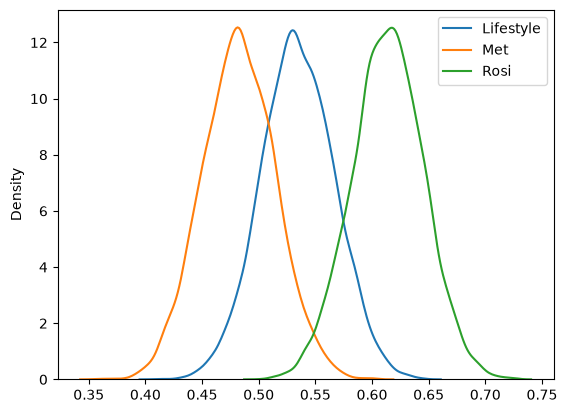

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.kdeplot(outcome_lif, label='Lifestyle')
sns.kdeplot(outcome_met, label='Met')
sns.kdeplot(outcome_ros, label='Rosi')

plt.legend()
plt.show()

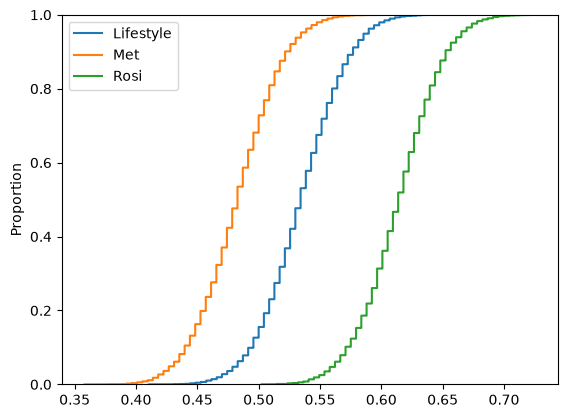

In [19]:
sns.ecdfplot(outcome_lif, label='Lifestyle')
sns.ecdfplot(outcome_met, label='Met')
sns.ecdfplot(outcome_ros, label='Rosi')

plt.legend()
plt.show()

All three ecdf plots follow a rough normal distribution. Rosi appears to have the most succesful outcomes on average, followed by lifestyle and then met.

# 4.

In [23]:
import numpy as np

#Lifestyle v.s. Met
ate_lif_met = np.array(outcome_lif) - np.array(outcome_met)

#Lifestyle v.s. Rosi
ate_lif_ros = np.array(outcome_lif) - np.array(outcome_ros)

#Rosi v.s. Met
ate_ros_met = np.array(outcome_ros) - np.array(outcome_met)

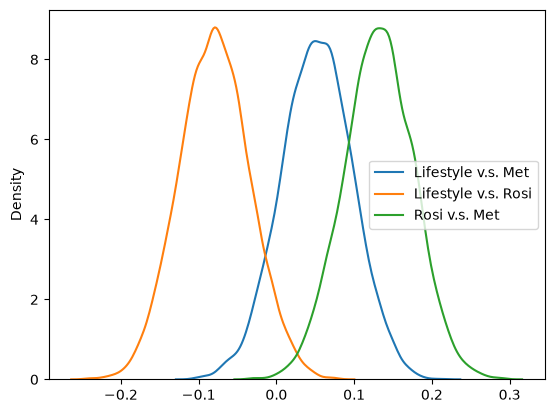

In [25]:
sns.kdeplot(ate_lif_met, label='Lifestyle v.s. Met')
sns.kdeplot(ate_lif_ros, label='Lifestyle v.s. Rosi')
sns.kdeplot(ate_ros_met, label='Rosi v.s. Met')

plt.legend()
plt.show()

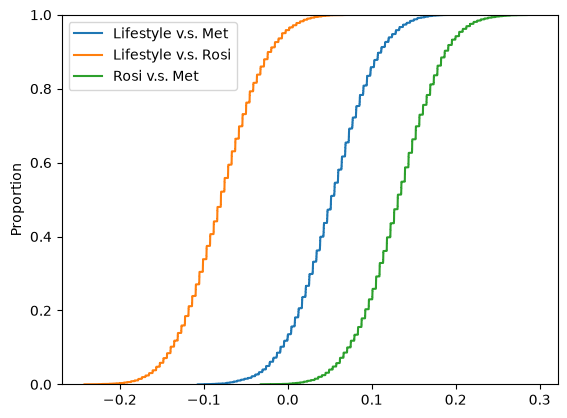

In [26]:
sns.ecdfplot(ate_lif_met, label='Lifestyle v.s. Met')
sns.ecdfplot(ate_lif_ros, label='Lifestyle v.s. Rosi')
sns.ecdfplot(ate_ros_met, label='Rosi v.s. Met')

plt.legend()
plt.show()

# 5.

In [ ]:
#Lifestyle v.s. Met:

ci90 = np.quantile(ate_lif_met, [.05, .95])
ci95 = np.quantile(ate_lif_met, [.025, .975])
ci99 = np.quantile(ate_lif_met, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.02199565  0.12849985]
95% CI: [-0.03864574  0.14143181]
99% CI: [-0.06867116  0.16714559]


In [28]:
#Lifestyle v.s. Rosi:
ci90 = np.quantile(ate_lif_ros, [.05, .95])
ci95 = np.quantile(ate_lif_ros, [.025, .975])
ci99 = np.quantile(ate_lif_ros, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.15243388 -0.00651113]
95% CI: [-0.16530942  0.01039947]
99% CI: [-0.19100547  0.03615054]


In [29]:
#Rosi v.s. Met:
ci90 = np.quantile(ate_ros_met, [.05, .95])
ci95 = np.quantile(ate_ros_met, [.025, .975])
ci99 = np.quantile(ate_ros_met, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [0.05777342 0.20414015]
95% CI: [0.0408826  0.21716368]
99% CI: [0.01483647 0.24724369]


Based on these plots, there is strong evidence that the Rosi treatment is stronger than the met treatment. The Rosi treatment had a positive effect over the met treatment at all three confidence levels. The Rosi treatment also had a positive effect over the Lifestyle treatment at the 90% level. There is not enough evidence to determone which treatment had a stronger effect between the met and lifestyle treatments, as 0 is present on all thre confidence intervals.